# 04 - Visualização (módulo 5)

Heatmaps de assinatura, histogramas, boxplot/violin, PCA e correlação, todos filtráveis por domínio/família/variável/fase/ordem/estatística/rótulo.

In [1]:
import matplotlib
import pandas as pd
from harmonic_signatures.config import PROCESSED_DIR
from harmonic_signatures.visualization.heatmaps import plot_signature_heatmap, plot_correlation_heatmap
from harmonic_signatures.visualization.distributions import plot_histogram, plot_boxplot, plot_violin
from harmonic_signatures.visualization.dimensionality import compute_embedding, plot_embedding_2d

harm_long = pd.read_parquet(PROCESSED_DIR / 'harmonicas_long.parquet')
harm_matrix = pd.read_parquet(PROCESSED_DIR / 'combined_matrix.parquet')

## Mapa de assinatura (corrente Ia, avg, H1-H25) por rótulo

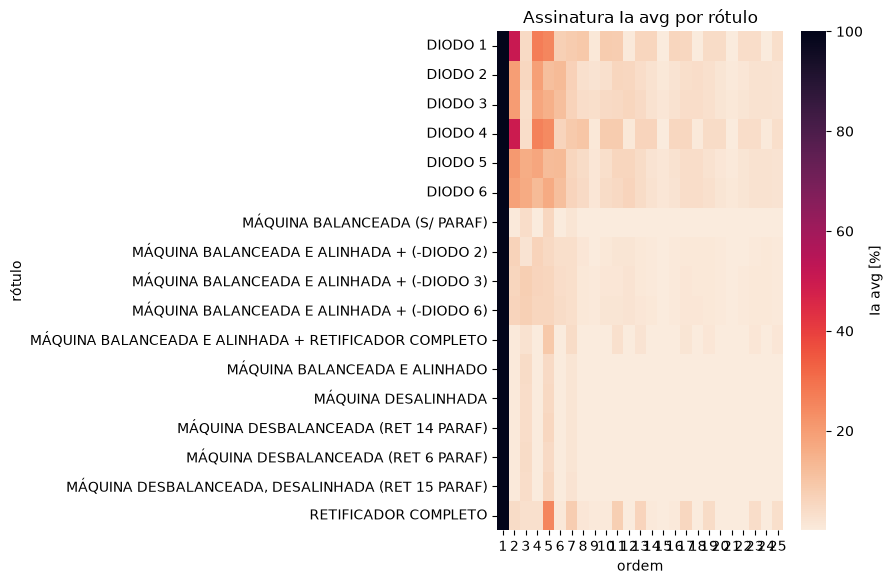

In [2]:
fig = plot_signature_heatmap(harm_long, variable='I', phase='a', statistic='avg', family='H', order_range=(1, 25))

## Distribuição de H5 Ia avg (boxplot e violin por rótulo)

C:\Users\Filipe Fraga\Documents\Doutorado\Modelo\src\harmonic_signatures\visualization\distributions.py:40: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


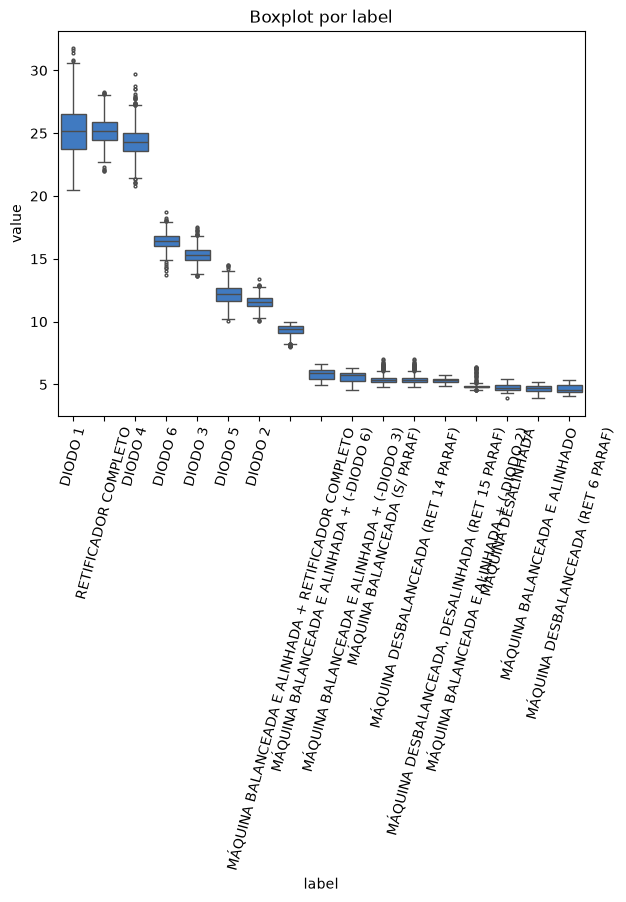

In [3]:
fig_box = plot_boxplot(harm_long, family='H', variable='I', phase='a', order=5, statistic='avg')

C:\Users\Filipe Fraga\Documents\Doutorado\Modelo\src\harmonic_signatures\visualization\distributions.py:54: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


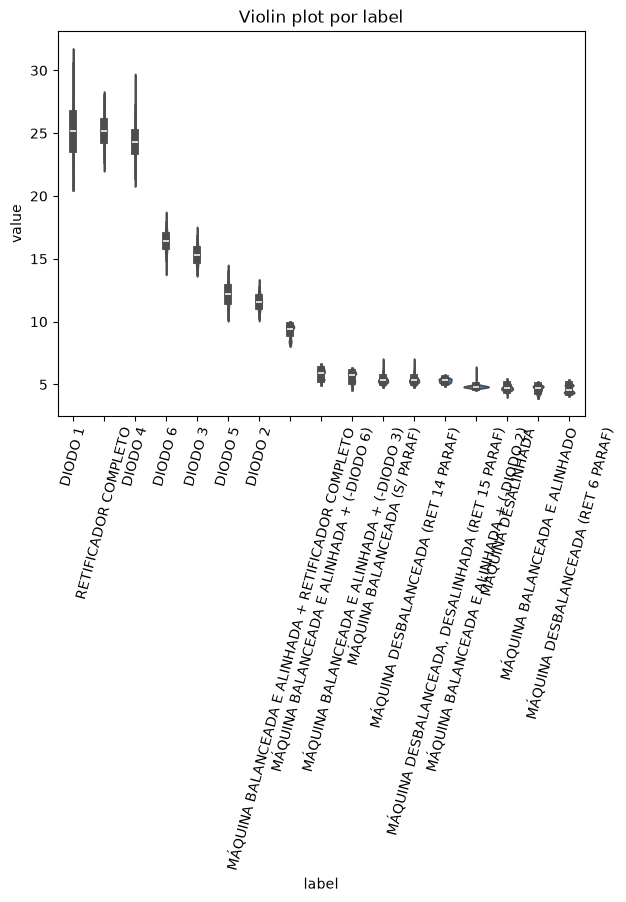

In [4]:
fig_violin = plot_violin(harm_long, family='H', variable='I', phase='a', order=5, statistic='avg')

## PCA — separabilidade das condições usando as 20 primeiras features H*_Ia_avg

variância explicada: [0.73753064 0.14993813]


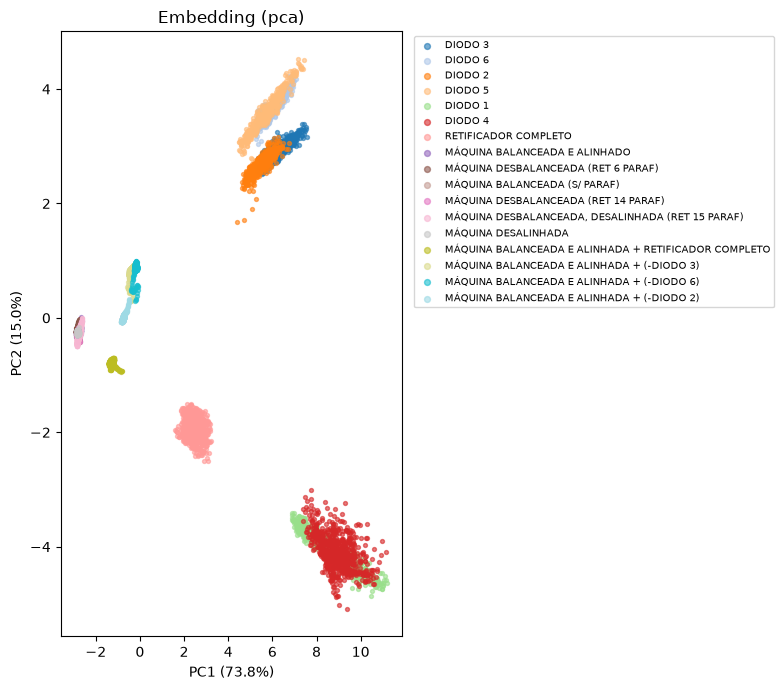

In [5]:
feature_cols = [c for c in harm_matrix.columns if c.startswith('H') and '_Ia_avg' in c and '_harm' not in c and '_inter' not in c][:20]
emb = compute_embedding(harm_matrix, feature_cols, method='pca', n_components=2)
print('variância explicada:', emb.attrs['explained_variance_ratio'])
fig_pca = plot_embedding_2d(emb)

## Correlação entre as features selecionadas

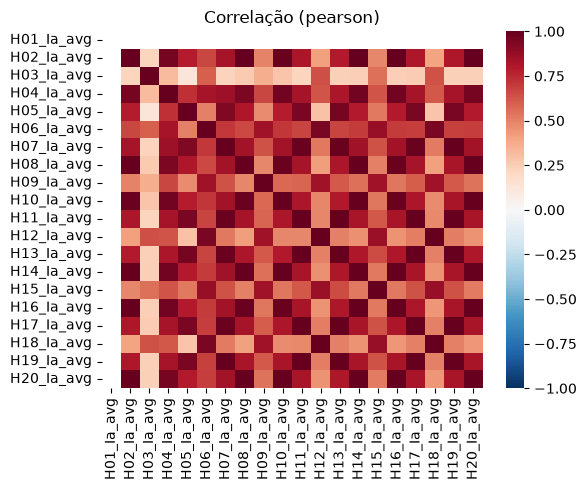

In [6]:
fig_corr = plot_correlation_heatmap(harm_matrix, feature_cols=feature_cols)